# Xử lý ảnh mắt phục vụ eye tracking

Notebook trình bày thuật toán **xử lý ảnh số truyền thống**, không dùng ML: thu nhận ảnh → gamma → trung vị → chọn kênh → Gaussian → giãn tương phản → phân ngưỡng → hình thái học → ellipse và tâm đồng tử.

Đây là phiên bản thuật toán **ảnh tĩnh Python** của demo. Video trên trình duyệt có cách triển khai và tham số riêng trong `webcam.js`.

**Cách dùng:** mở bằng JupyterLab hoặc VS Code, chọn Python kernel rồi **Run All**. Giữ thư mục `data` cạnh notebook. Sửa `IMAGE_NAME`, `CONDITION` và `THRESHOLD` ở ô cấu hình rồi chạy lại các ô phía dưới. Ảnh đầu ra đã được lưu trong notebook để xem ngay.

Các vùng sáng, tối, nhiễu mô phỏng được ghi rõ. Tâm đồng tử chỉ là ước lượng; chưa có nhãn chuẩn để công bố độ chính xác hoặc hiệu chuẩn điểm nhìn.

## 1. Thư viện và hàm hiển thị
Nếu thiếu thư viện, bỏ dấu `#` ở dòng `%pip` bên dưới rồi chạy lại kernel. Lần cài đầu cần internet; các bước xử lý không cần mạng.

In [1]:
# %pip install -r requirements-notebook.txt
from pathlib import Path
import csv
import json
import math
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 100, 'font.size': 11})

def show(images, titles, columns=2):
    rows = math.ceil(len(images) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 3.5 * rows), squeeze=False)
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis('off')
    for ax in list(axes.flat)[len(images):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [2]:
def read_image(path):
    image = cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Cannot read image: {path}')
    return image

def histogram_panel(before, after):
    panel = np.full((400, 768, 3), 245, np.uint8)
    histograms = [cv2.calcHist([im], [0], None, [256], [0,256]).ravel() for im in (before,after)]
    maximum = max(float(h.max()) for h in histograms)
    for hist, color, label, ypos in zip(histograms, [(190,90,20),(30,150,30)], ['Input grayscale','After gamma + median'], [25,50]):
        points = np.array([[int(40+i*2.6),int(355-v/maximum*280)] for i,v in enumerate(hist)],np.int32)
        cv2.polylines(panel,[points],False,color,2)
        cv2.putText(panel,label,(40,ypos),cv2.FONT_HERSHEY_SIMPLEX,.55,color,1)
    cv2.line(panel,(40,355),(705,355),(60,60,60),1)
    for i in [0,64,128,192,255]:
        cv2.putText(panel,str(i),(int(35+i*2.6),380),cv2.FONT_HERSHEY_SIMPLEX,.45,(50,50,50),1)
    return panel

## 2. Chọn ảnh và điều kiện thử nghiệm
Ảnh gốc giữ nguyên trong `data`. Các điều kiện bright, dark, noise là biến thể tổng hợp; không đại diện cho các lần thu camera riêng.

Ảnh: Videoshot_20261026_002227.jpg | Điều kiện: original | Kích thước: (2304, 4096, 3)


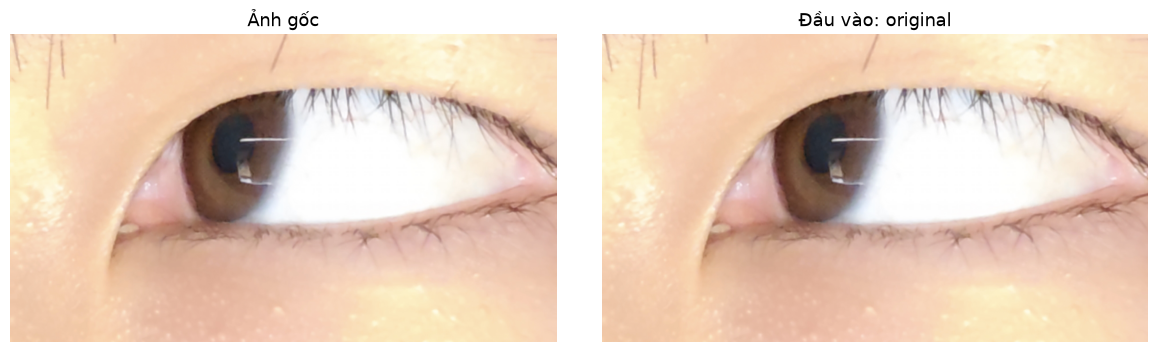

In [3]:
ROOT = Path.cwd()
if not (ROOT / 'data').is_dir() and (ROOT.parent / 'data').is_dir():
    ROOT = ROOT.parent
DATA_DIR = ROOT / 'data'
IMAGE_NAME = 'Videoshot_20261026_002227.jpg'
CONDITION = 'original'  # original | bright | dark | noise
THRESHOLD = None       # None: tìm ngưỡng 5–100; hoặc đặt số nguyên 0–255

if CONDITION not in {'original', 'bright', 'dark', 'noise'}:
    raise ValueError('Điều kiện không hợp lệ')
if THRESHOLD is not None and (not isinstance(THRESHOLD, int) or not 0 <= THRESHOLD <= 255):
    raise ValueError('THRESHOLD cần là None hoặc số nguyên 0–255')
original_image = read_image(DATA_DIR / IMAGE_NAME)
image = original_image.copy()
if CONDITION == 'bright':
    image = np.clip(image.astype(np.float32)*1.35 + 35, 0, 255).astype(np.uint8)
elif CONDITION == 'dark':
    image = np.clip(image.astype(np.float32)*.28, 0, 255).astype(np.uint8)
elif CONDITION == 'noise':
    rng = np.random.default_rng(42)
    image = np.clip(image.astype(np.float32) + rng.normal(0, 28, image.shape), 0, 255).astype(np.uint8)
threshold = THRESHOLD
print('Ảnh:', IMAGE_NAME, '| Điều kiện:', CONDITION, '| Kích thước:', image.shape)
show([original_image, image], ['Ảnh gốc', f'Đầu vào: {CONDITION}'])

## 3. Thu nhỏ và xác định vùng mắt
Chiều rộng tối đa 1024 px. ROI cố định x=18%–87%, y=20%–85% phù hợp ảnh một mắt cận cảnh. Đây không phải bộ phát hiện mắt trên toàn khuôn mặt.

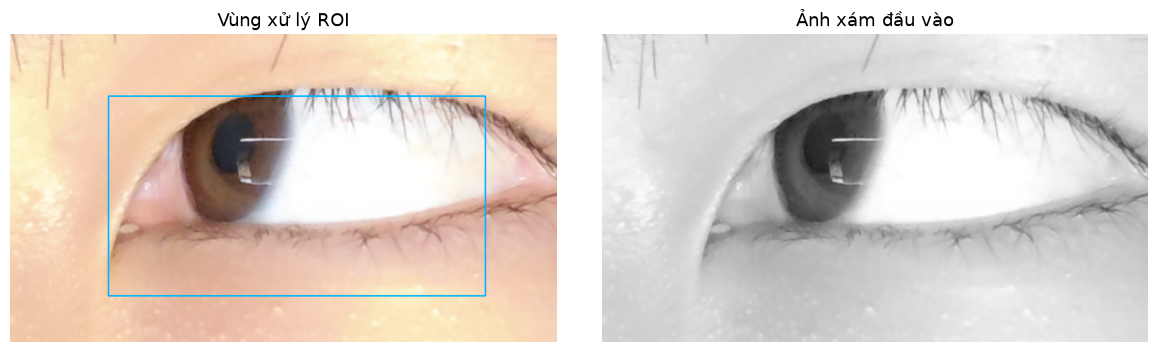

In [4]:
start = time.perf_counter()
h0, w0 = image.shape[:2]
scale = min(1.0, 1024 / w0)
frame = cv2.resize(image, (round(w0 * scale), round(h0 * scale)))
h, w = frame.shape[:2]
x0, y0, x1, y1 = int(.18*w), int(.20*h), int(.87*w), int(.85*h)
input_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
roi_preview = frame.copy()
cv2.rectangle(roi_preview, (x0, y0), (x1, y1), (255, 180, 0), 2)
show([roi_preview, input_gray], ['Vùng xử lý ROI', 'Ảnh xám đầu vào'])

## 4. Hiệu chỉnh độ sáng bằng gamma

$$s = 255\left(\frac{r}{255}\right)^\gamma$$

Gamma < 1 làm sáng, gamma > 1 làm tối. Chọn gamma từ trung vị mức xám, mục tiêu 130; chặn trong 0.4–1.4 và giữ gamma=1 nếu trung vị 90–170. Đây là quy tắc thử nghiệm. Vùng đã cháy sáng mất chi tiết không được tái tạo bằng gamma.

Trung vị đầu vào: 216.0; gamma: 1.400


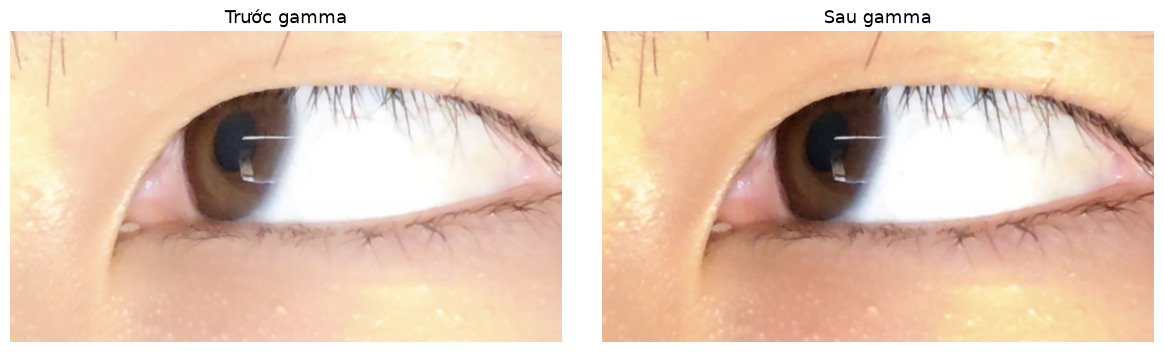

In [5]:
median = float(np.median(input_gray))
gamma = float(np.clip(math.log(130/255)/math.log(max(1, min(254, median))/255), .4, 1.4)) if not 90 <= median <= 170 else 1.0
lut = np.array([round(255*(i/255)**gamma) for i in range(256)], dtype=np.uint8)
balanced = cv2.LUT(frame, lut)
print(f'Trung vị đầu vào: {median:.1f}; gamma: {gamma:.3f}')
show([frame, balanced], ['Trước gamma', 'Sau gamma'])

## 5. Lọc trung vị và quan sát histogram
Trung vị 5×5 thay giá trị pixel bằng trung vị lân cận, xử lý từng kênh màu. Có thể giảm nhiễu điểm nhưng cũng làm mất chi tiết nhỏ. Histogram là biểu đồ phân bố mức sáng, không phải thao tác cân bằng histogram.

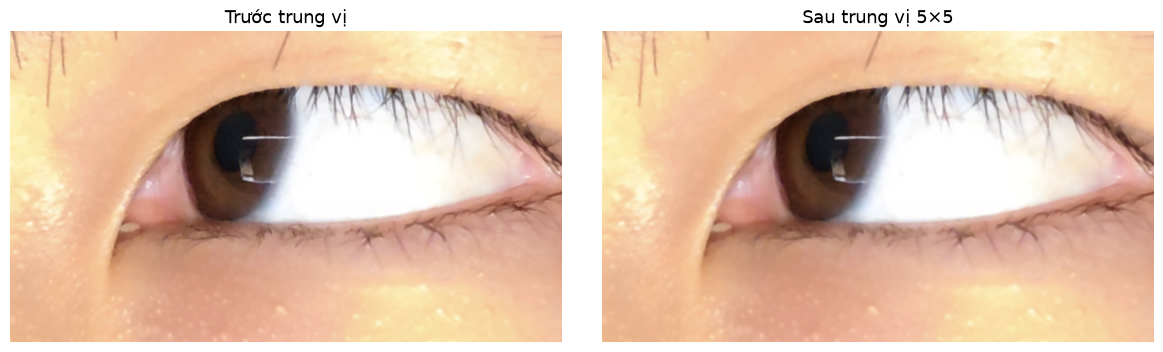

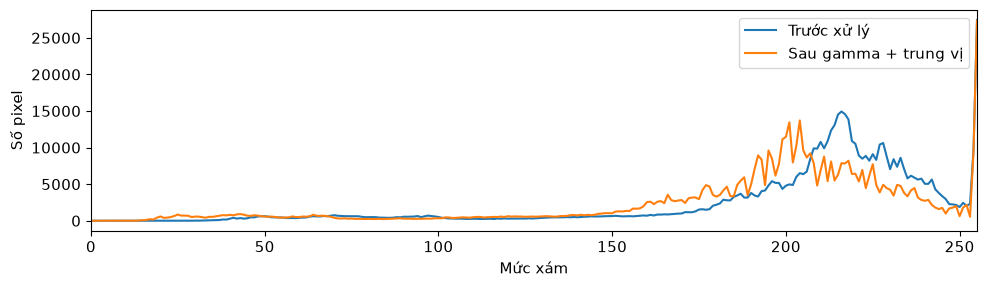

In [6]:
denoised = cv2.medianBlur(balanced, 5)
show([balanced, denoised], ['Trước trung vị', 'Sau trung vị 5×5'])

fig, ax = plt.subplots(figsize=(10, 3))
for label, img in [('Trước xử lý', input_gray), ('Sau gamma + trung vị', cv2.cvtColor(denoised, cv2.COLOR_BGR2GRAY))]:
    ax.plot(cv2.calcHist([img], [0], None, [256], [0, 256]).ravel(), label=label)
ax.set(xlabel='Mức xám', ylabel='Số pixel', xlim=(0, 255))
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)

## 6. Chọn kênh ảnh và lọc Gaussian
Trên bộ ảnh này, đồng tử xanh đen tối hơn mống mắt nâu ở kênh đỏ. Ảnh xám được hiển thị để đối chiếu; phân đoạn sử dụng **kênh đỏ**. Cần đánh giá lại lựa chọn này với dữ liệu IR. Gaussian 7×7 giảm nhiễu và làm mịn biên.

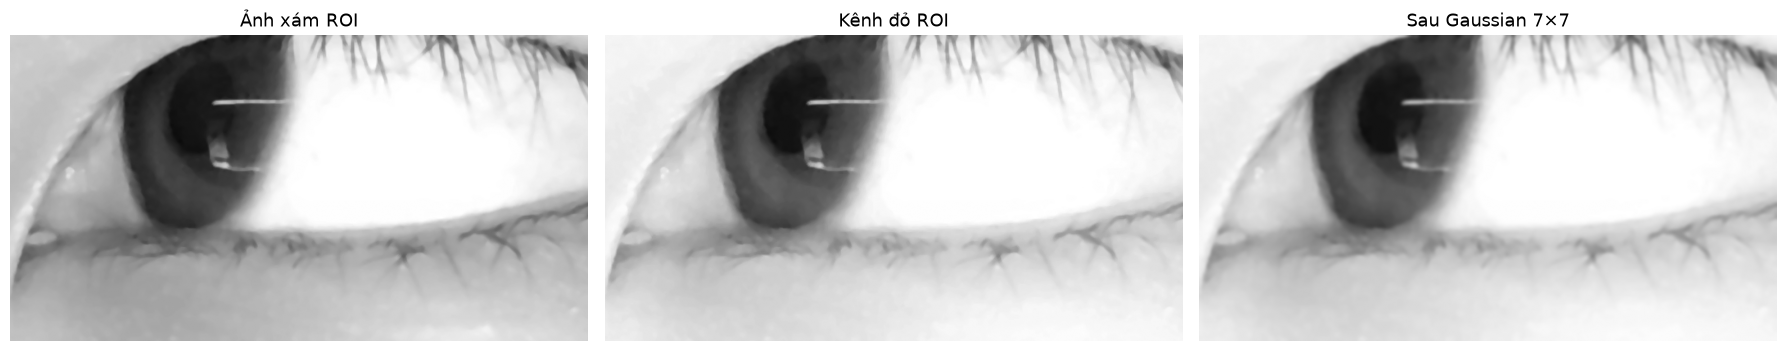

In [7]:
roi = denoised[y0:y1, x0:x1]
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
red = roi[:, :, 2]
smooth = cv2.GaussianBlur(red, (7, 7), 0)
show([gray, red, smooth], ['Ảnh xám ROI', 'Kênh đỏ ROI', 'Sau Gaussian 7×7'], columns=3)

## 7. Giãn tương phản
Lấy phân vị 2% và 98% làm hai mốc, ánh xạ tuyến tính về 0–255 và cắt ngoài miền. Các mốc được tính trên ROI sau Gaussian; không dùng CLAHE hay cân bằng histogram.

Mốc thấp: 31.0; mốc cao: 255.0


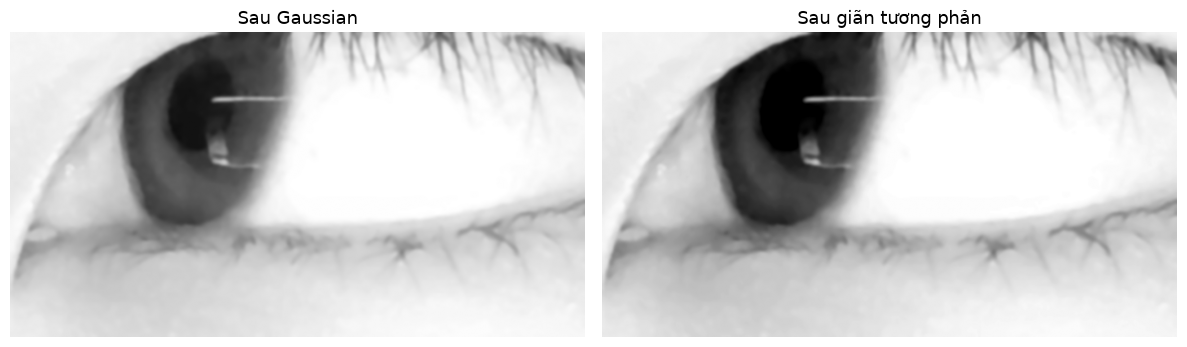

In [8]:
low, high = np.percentile(smooth, (2, 98))
enhanced = np.clip((smooth.astype(np.float32)-low)*255/max(1, high-low), 0, 255).astype(np.uint8)
print(f'Mốc thấp: {low:.1f}; mốc cao: {high:.1f}')
show([smooth, enhanced], ['Sau Gaussian', 'Sau giãn tương phản'])

## 8. Phân ngưỡng và hình thái học
Minh họa ngưỡng 40 nếu cấu hình tự động. Ngưỡng đảo biến vùng tối thành trắng. Đóng hai lần và mở một lần với phần tử cấu trúc ellipse 5×5. Ở bước sau, thuật toán thử các ngưỡng để chọn vùng ứng viên tốt nhất.

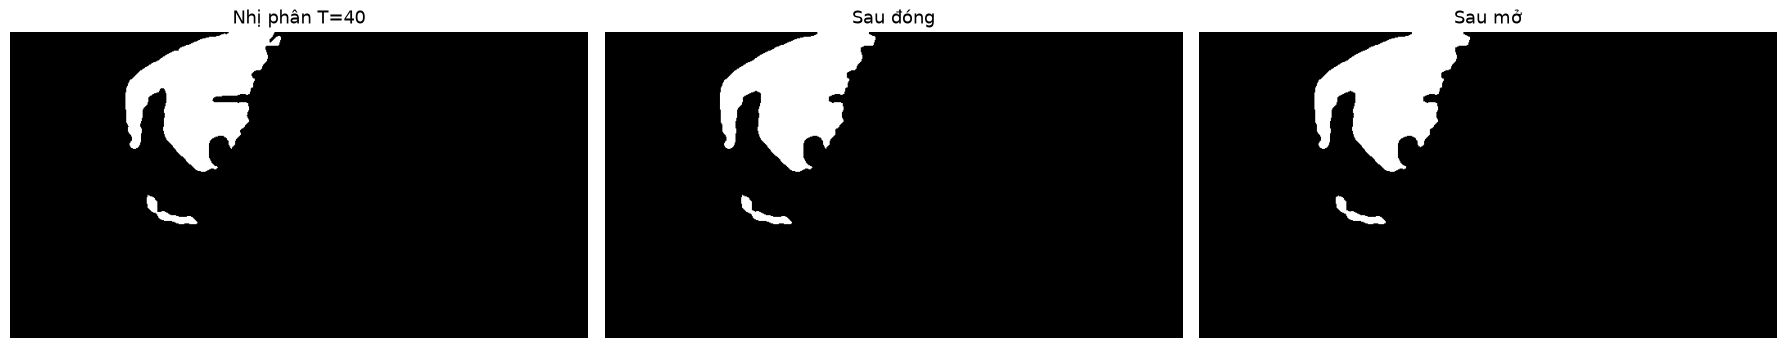

In [9]:
preview_threshold = 40 if threshold is None else threshold
_, preview_binary = cv2.threshold(enhanced, preview_threshold, 255, cv2.THRESH_BINARY_INV)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
preview_closed = cv2.morphologyEx(preview_binary, cv2.MORPH_CLOSE, kernel, iterations=2)
preview_clean = cv2.morphologyEx(preview_closed, cv2.MORPH_OPEN, kernel)
show([preview_binary, preview_closed, preview_clean],
     [f'Nhị phân T={preview_threshold}', 'Sau đóng', 'Sau mở'], columns=3)

## 9. Lựa chọn contour bằng đặc trưng hình dạng

Trên ảnh màu nâu rõ (phân vị 75% của R−B > 20), kết hợp R−B ≤ 8 và mức xám < 200 để giảm vùng mống mắt/mí mắt nâu và phản xạ mạnh. Ảnh gần trung tính tự bỏ điều kiện màu. Đây là quy tắc cho bộ mẫu, cần kiểm tra lại với ảnh IR. Bước 8 minh họa ngưỡng đơn; bước này bổ sung điều kiện màu trước hình thái học.

- Diện tích vùng trong 1.8%–13% diện tích ROI; loại vùng chạm biên ROI.
- Độ tròn $4\pi A/P^2$, solidity $A/A_{hull}$, tỷ lệ trục ngắn/trục dài.
- Điểm xếp hạng: 0.45 × độ tròn + 0.25 × solidity + 0.20 × tỷ lệ trục + 0.10 × độ tối.

Ngưỡng tự động ở đây là **tìm kiếm ngưỡng 5–100 bước 5 theo điểm hình dạng**, không phải Otsu. Điểm xếp hạng không phải độ chính xác hay xác suất. Phần này là ứng dụng sau xử lý ảnh.

Ngưỡng được chọn: 60
{'area': 6321.0, 'circularity': 0.7826, 'solidity': 0.9681, 'aspect': 0.7164, 'score': 0.8356}


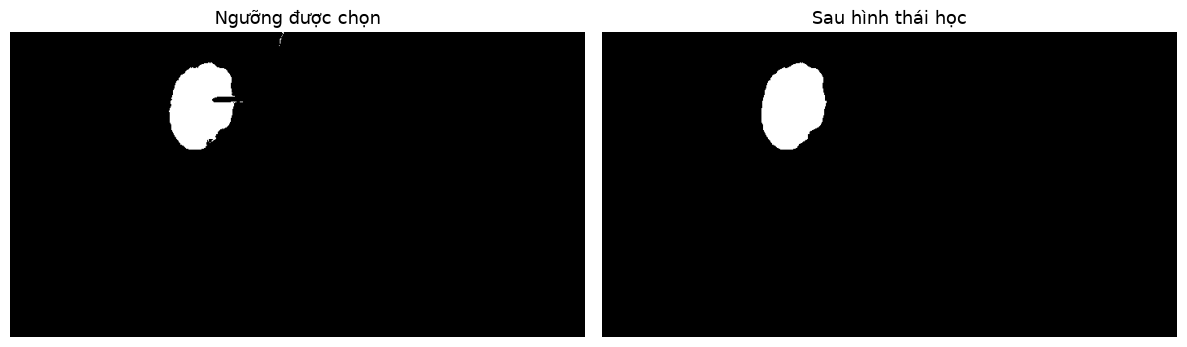

In [10]:
rh, rw = gray.shape
# In these visible-light color samples, brown iris/eyelid pixels can be
# as dark as the pupil in R alone. Reject their positive R-B chroma.
# Disable this gate on near-neutral images (e.g. monochrome IR).
red_blue = red.astype(np.int16) - roi[:, :, 0].astype(np.int16)
use_color_gate = bool(np.percentile(red_blue, 75) > 20)
color_gate = ((red_blue <= 8) & (gray < 200)).astype(np.uint8) * 255 if use_color_gate else np.full_like(gray, 255)
values = [threshold] if threshold is not None else list(range(5, 101, 5))
best = None
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
for t in values:
    _, binary = cv2.threshold(enhanced, t, 255, cv2.THRESH_BINARY_INV)
    binary = cv2.bitwise_and(binary, color_gate)
    clean = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=2)
    clean = cv2.morphologyEx(clean, cv2.MORPH_OPEN, kernel)
    contours, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in contours:
        area = cv2.contourArea(c)
        fraction = area/(rh*rw)
        if not .018 < fraction < .13 or len(c) < 5:
            continue
        x, y, cw, ch = cv2.boundingRect(c)
        if x <= 1 or y <= 1 or x+cw >= rw-1 or y+ch >= rh-1:
            continue
        perimeter = cv2.arcLength(c, True)
        circularity = 4*math.pi*area/max(perimeter**2, 1)
        solidity = area/max(cv2.contourArea(cv2.convexHull(c)), 1)
        ellipse = cv2.fitEllipse(c)
        (cx, cy), (a, b), angle = ellipse
        aspect = min(a,b)/max(a,b)
        if aspect < .4 or solidity < .65 or circularity < .3:
            continue
        mask = np.zeros_like(gray)
        cv2.drawContours(mask, [c], -1, 255, -1)
        darkness = 1-float(cv2.mean(enhanced, mask=mask)[0])/255
        score = .45*circularity + .25*solidity + .2*aspect + .1*darkness
        if best is None or score > best['score']:
            best = dict(score=score, contour=c, ellipse=ellipse, threshold=t,
                        area=area, circularity=circularity, solidity=solidity,
                        aspect=aspect, binary=binary, clean=clean)
if best is None:
    print('Chưa tìm được vùng hợp lệ. Kiểm tra ảnh, ROI và ngưỡng.')
else:
    print('Ngưỡng được chọn:', best['threshold'])
    print({key: round(best[key], 4) for key in ['area', 'circularity', 'solidity', 'aspect', 'score']})
    show([best['binary'], best['clean']], ['Ngưỡng được chọn', 'Sau hình thái học'])

## 10. Khớp ellipse và tâm đồng tử
Khớp ellipse trên contour, vẽ đường bao xanh và tâm đỏ. Chuyển tọa độ về ảnh gốc qua hệ số thu nhỏ. Phản xạ hoặc mí mắt che có thể làm tâm lệch. Không xuất tọa độ khi không có vùng hợp lệ.

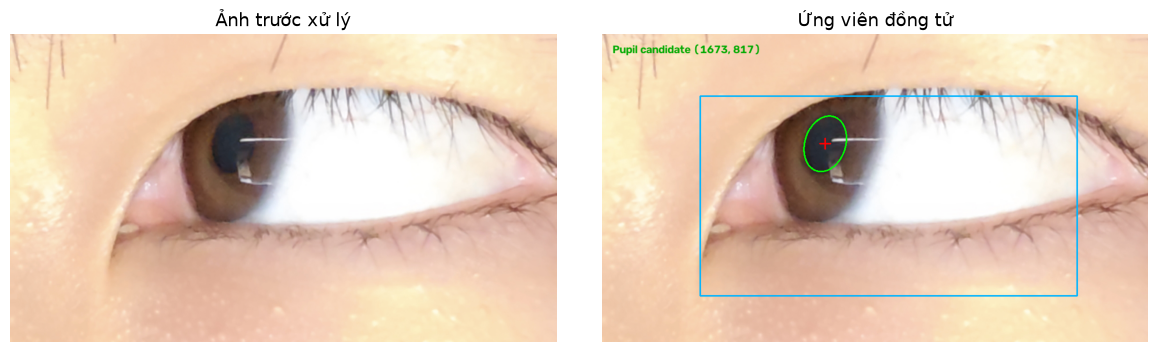

{'detected': True,
 'source_width': 4096,
 'source_height': 2304,
 'median_intensity': 216.0,
 'gamma': 1.4,
 'bright_clip_percent': 7.77,
 'dark_clip_percent': 0.0,
 'noise_proxy': 0.0,
 'color_gate': True,
 'center_x': 1672.63,
 'center_y': 817.1,
 'normalized_x': 0.4084,
 'normalized_y': 0.3546,
 'area_px': 101136.0,
 'circularity': 0.7826,
 'solidity': 0.9681,
 'axis_ratio': 0.7164,
 'threshold': 60,
 'selection_score': 0.8356}

In [11]:
overlay = frame.copy()
cv2.rectangle(overlay, (x0,y0), (x1,y1), (255,180,0), 2)
residual = input_gray.astype(np.float32)-cv2.medianBlur(input_gray, 5).astype(np.float32)
noise_proxy = float(np.median(np.abs(residual))/.6745)
metrics = {'detected': best is not None, 'source_width': w0, 'source_height': h0,
           'median_intensity': round(median,2), 'gamma': round(gamma,3),
           'bright_clip_percent': round(float(np.mean(input_gray>=250))*100,2),
           'dark_clip_percent': round(float(np.mean(input_gray<=5))*100,2),
           'noise_proxy': round(noise_proxy,2), 'color_gate': use_color_gate}
if best:
    (cx, cy), axes, angle = best['ellipse']
    center = (cx+x0, cy+y0)
    cv2.ellipse(overlay, (center, axes, angle), (0,255,0), 2)
    cv2.drawMarker(overlay, tuple(round(v) for v in center), (0,0,255), cv2.MARKER_CROSS, 20, 2)
    cv2.putText(overlay, f'Pupil candidate ({center[0]/scale:.0f}, {center[1]/scale:.0f})', (20,35), cv2.FONT_HERSHEY_SIMPLEX, .7, (0,170,0), 2)
    metrics.update(center_x=round(center[0]/scale,2), center_y=round(center[1]/scale,2),
                   normalized_x=round(center[0]/w,4), normalized_y=round(center[1]/h,4),
                   area_px=round(best['area']/scale**2,2),
                   circularity=round(best['circularity'],4), solidity=round(best['solidity'],4),
                   axis_ratio=round(best['aspect'],4), threshold=best['threshold'],
                   selection_score=round(best['score'],4))
    binary, clean = best['binary'], best['clean']
else:
    _, binary = cv2.threshold(enhanced, threshold if threshold is not None else 50, 255, cv2.THRESH_BINARY_INV)
    binary = cv2.bitwise_and(binary, color_gate)
    clean = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    cv2.putText(overlay, 'NO VALID CANDIDATE', (20,35), cv2.FONT_HERSHEY_SIMPLEX, .8, (0,0,255), 2)
# Không tính thời gian giữa các cell vì bao gồm thời gian người dùng thao tác.
stages = {'original':frame, 'balanced':balanced, 'denoised':denoised,
          'histogram':histogram_panel(input_gray,cv2.cvtColor(denoised,cv2.COLOR_BGR2GRAY)),
          'gray':gray, 'red':red, 'enhanced':enhanced,
          'binary':binary, 'clean':clean, 'result':overlay}
show([frame, overlay], ['Ảnh trước xử lý', 'Ứng viên đồng tử'])
display(metrics)

## 11. Thí nghiệm nhiễu có ảnh tham chiếu
Tạo nhiễu Gaussian σ=20 và muối tiêu 4% trên ảnh xám đã thu nhỏ từ **ảnh gốc**. So sánh trung vị và Gaussian 5×5. PSNR chỉ đo sai khác với ảnh trước khi thêm nhiễu; không đo độ chính xác tâm hoặc chất lượng của ảnh mắt lý tưởng. Thí nghiệm này độc lập với CONDITION đã chọn phía trên.

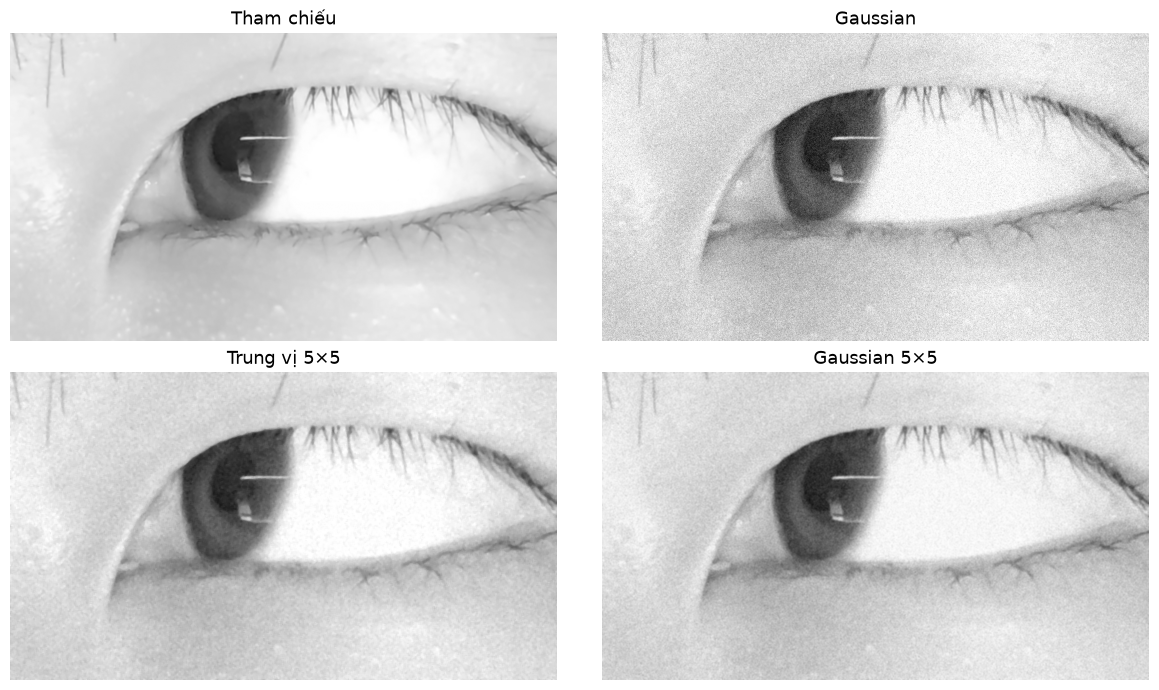

{'noise': 'Gaussian', 'input_psnr_db': 22.61, 'median_psnr_db': 33.72, 'gaussian_psnr_db': 32.74}


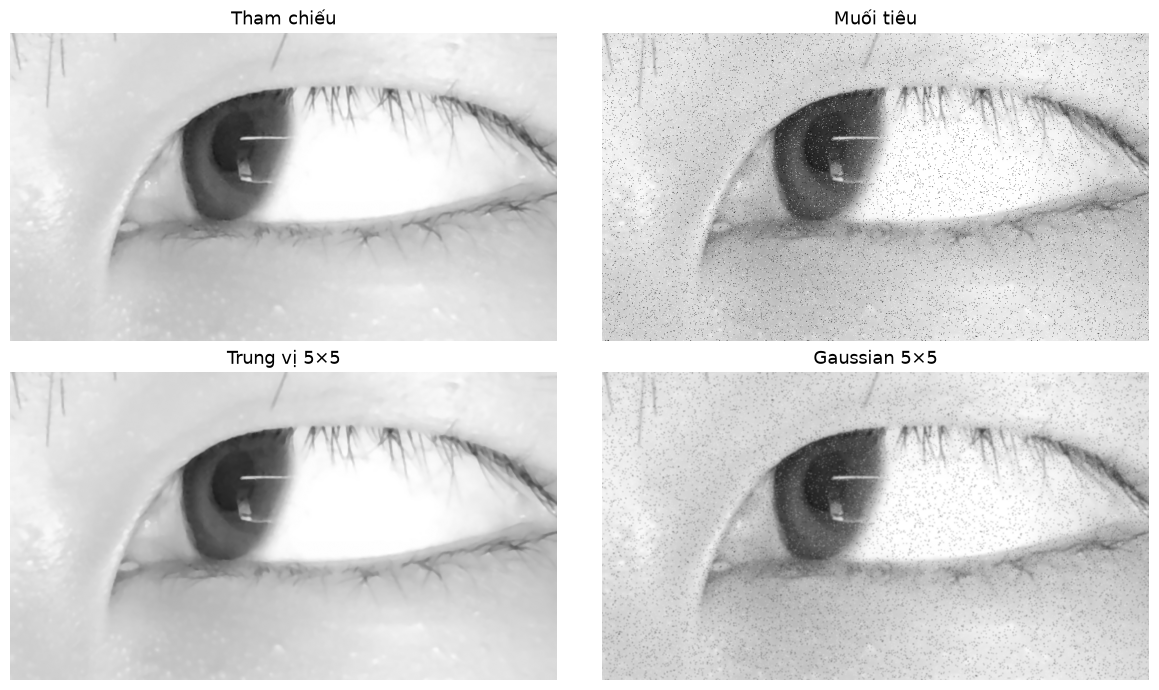

{'noise': 'Muối tiêu', 'input_psnr_db': 18.21, 'median_psnr_db': 46.06, 'gaussian_psnr_db': 28.71}


In [12]:
reference_frame = cv2.resize(original_image, (w, h))
reference = cv2.cvtColor(reference_frame, cv2.COLOR_BGR2GRAY)
rng = np.random.default_rng(42)
noisy_gaussian = np.clip(reference.astype(np.float32) + rng.normal(0, 20, reference.shape), 0, 255).astype(np.uint8)
noisy_impulse = reference.copy()
random_values = rng.random(reference.shape)
noisy_impulse[random_values < .02] = 0
noisy_impulse[random_values > .98] = 255
noise_records = []
for noise_name, noisy in [('Gaussian', noisy_gaussian), ('Muối tiêu', noisy_impulse)]:
    filtered_median = cv2.medianBlur(noisy, 5)
    filtered_gaussian = cv2.GaussianBlur(noisy, (5, 5), 0)
    record = {'noise': noise_name,
              'input_psnr_db': round(cv2.PSNR(reference, noisy), 2),
              'median_psnr_db': round(cv2.PSNR(reference, filtered_median), 2),
              'gaussian_psnr_db': round(cv2.PSNR(reference, filtered_gaussian), 2)}
    noise_records.append(record)
    show([reference, noisy, filtered_median, filtered_gaussian],
         ['Tham chiếu', noise_name, 'Trung vị 5×5', 'Gaussian 5×5'], columns=2)
    print(record)

## 12. Hàm tổng hợp để xử lý nhiều ảnh
Hàm bên dưới gom đúng các bước vừa trình bày, cùng tham số với `analyze` trong `eye_tracking.py`. Mã được giữ ngay trong notebook để có thể chạy độc lập với file Python. Phần đo thời gian ở đây chỉ bao gồm xử lý trong hàm, không gồm đọc ảnh và vẽ biểu đồ.

In [13]:
def analyze(image, threshold=None):
    """Fixed broad ROI assumes a single close-up eye, as in supplied samples.

    Threshold red channel: brown iris is brighter than blue/black pupil here.
    This is a visible-light sample-specific choice, not an IR calibration.
    """
    start = time.perf_counter()
    h0, w0 = image.shape[:2]
    scale = min(1.0, 1024 / w0)
    frame = cv2.resize(image, (round(w0 * scale), round(h0 * scale)))
    h, w = frame.shape[:2]
    x0, y0, x1, y1 = int(.18*w), int(.20*h), int(.87*w), int(.85*h)
    input_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    median = float(np.median(input_gray))
    gamma = float(np.clip(math.log(130/255)/math.log(max(1, min(254, median))/255), .4, 1.4)) if not 90 <= median <= 170 else 1.0
    lut = np.array([round(255*(i/255)**gamma) for i in range(256)], dtype=np.uint8)
    balanced = cv2.LUT(frame, lut)
    denoised = cv2.medianBlur(balanced, 5)
    roi = denoised[y0:y1, x0:x1]
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    red = roi[:, :, 2]
    smooth = cv2.GaussianBlur(red, (7, 7), 0)
    low, high = np.percentile(smooth, (2, 98))
    enhanced = np.clip((smooth.astype(np.float32)-low)*255/max(1, high-low), 0, 255).astype(np.uint8)
    rh, rw = gray.shape
    # In these visible-light color samples, brown iris/eyelid pixels can be
    # as dark as the pupil in R alone. Reject their positive R-B chroma.
    # Disable this gate on near-neutral images (e.g. monochrome IR).
    red_blue = red.astype(np.int16) - roi[:, :, 0].astype(np.int16)
    use_color_gate = bool(np.percentile(red_blue, 75) > 20)
    color_gate = ((red_blue <= 8) & (gray < 200)).astype(np.uint8) * 255 if use_color_gate else np.full_like(gray, 255)
    values = [threshold] if threshold is not None else list(range(5, 101, 5))
    best = None
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    for t in values:
        _, binary = cv2.threshold(enhanced, t, 255, cv2.THRESH_BINARY_INV)
        binary = cv2.bitwise_and(binary, color_gate)
        clean = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=2)
        clean = cv2.morphologyEx(clean, cv2.MORPH_OPEN, kernel)
        contours, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in contours:
            area = cv2.contourArea(c)
            fraction = area/(rh*rw)
            if not .018 < fraction < .13 or len(c) < 5:
                continue
            x, y, cw, ch = cv2.boundingRect(c)
            if x <= 1 or y <= 1 or x+cw >= rw-1 or y+ch >= rh-1:
                continue
            perimeter = cv2.arcLength(c, True)
            circularity = 4*math.pi*area/max(perimeter**2, 1)
            solidity = area/max(cv2.contourArea(cv2.convexHull(c)), 1)
            ellipse = cv2.fitEllipse(c)
            (cx, cy), (a, b), angle = ellipse
            aspect = min(a,b)/max(a,b)
            if aspect < .4 or solidity < .65 or circularity < .3:
                continue
            mask = np.zeros_like(gray)
            cv2.drawContours(mask, [c], -1, 255, -1)
            darkness = 1-float(cv2.mean(enhanced, mask=mask)[0])/255
            score = .45*circularity + .25*solidity + .2*aspect + .1*darkness
            if best is None or score > best['score']:
                best = dict(score=score, contour=c, ellipse=ellipse, threshold=t,
                            area=area, circularity=circularity, solidity=solidity,
                            aspect=aspect, binary=binary, clean=clean)
    overlay = frame.copy()
    cv2.rectangle(overlay, (x0,y0), (x1,y1), (255,180,0), 2)
    residual = input_gray.astype(np.float32)-cv2.medianBlur(input_gray, 5).astype(np.float32)
    noise_proxy = float(np.median(np.abs(residual))/.6745)
    metrics = {'detected': best is not None, 'source_width': w0, 'source_height': h0,
               'median_intensity': round(median,2), 'gamma': round(gamma,3),
               'bright_clip_percent': round(float(np.mean(input_gray>=250))*100,2),
               'dark_clip_percent': round(float(np.mean(input_gray<=5))*100,2),
               'noise_proxy': round(noise_proxy,2), 'color_gate': use_color_gate}
    if best:
        (cx, cy), axes, angle = best['ellipse']
        center = (cx+x0, cy+y0)
        cv2.ellipse(overlay, (center, axes, angle), (0,255,0), 2)
        cv2.drawMarker(overlay, tuple(round(v) for v in center), (0,0,255), cv2.MARKER_CROSS, 20, 2)
        cv2.putText(overlay, f'Pupil candidate ({center[0]/scale:.0f}, {center[1]/scale:.0f})', (20,35), cv2.FONT_HERSHEY_SIMPLEX, .7, (0,170,0), 2)
        metrics.update(center_x=round(center[0]/scale,2), center_y=round(center[1]/scale,2),
                       normalized_x=round(center[0]/w,4), normalized_y=round(center[1]/h,4),
                       area_px=round(best['area']/scale**2,2),
                       circularity=round(best['circularity'],4), solidity=round(best['solidity'],4),
                       axis_ratio=round(best['aspect'],4), threshold=best['threshold'],
                       selection_score=round(best['score'],4))
        binary, clean = best['binary'], best['clean']
    else:
        _, binary = cv2.threshold(enhanced, threshold if threshold is not None else 50, 255, cv2.THRESH_BINARY_INV)
        binary = cv2.bitwise_and(binary, color_gate)
        clean = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
        cv2.putText(overlay, 'NO VALID CANDIDATE', (20,35), cv2.FONT_HERSHEY_SIMPLEX, .8, (0,0,255), 2)
    metrics['processing_ms'] = round((time.perf_counter()-start)*1000,2)
    stages = {'original':frame, 'balanced':balanced, 'denoised':denoised,
              'histogram':histogram_panel(input_gray,cv2.cvtColor(denoised,cv2.COLOR_BGR2GRAY)),
              'gray':gray, 'red':red, 'enhanced':enhanced,
              'binary':binary, 'clean':clean, 'result':overlay}
    return metrics, stages

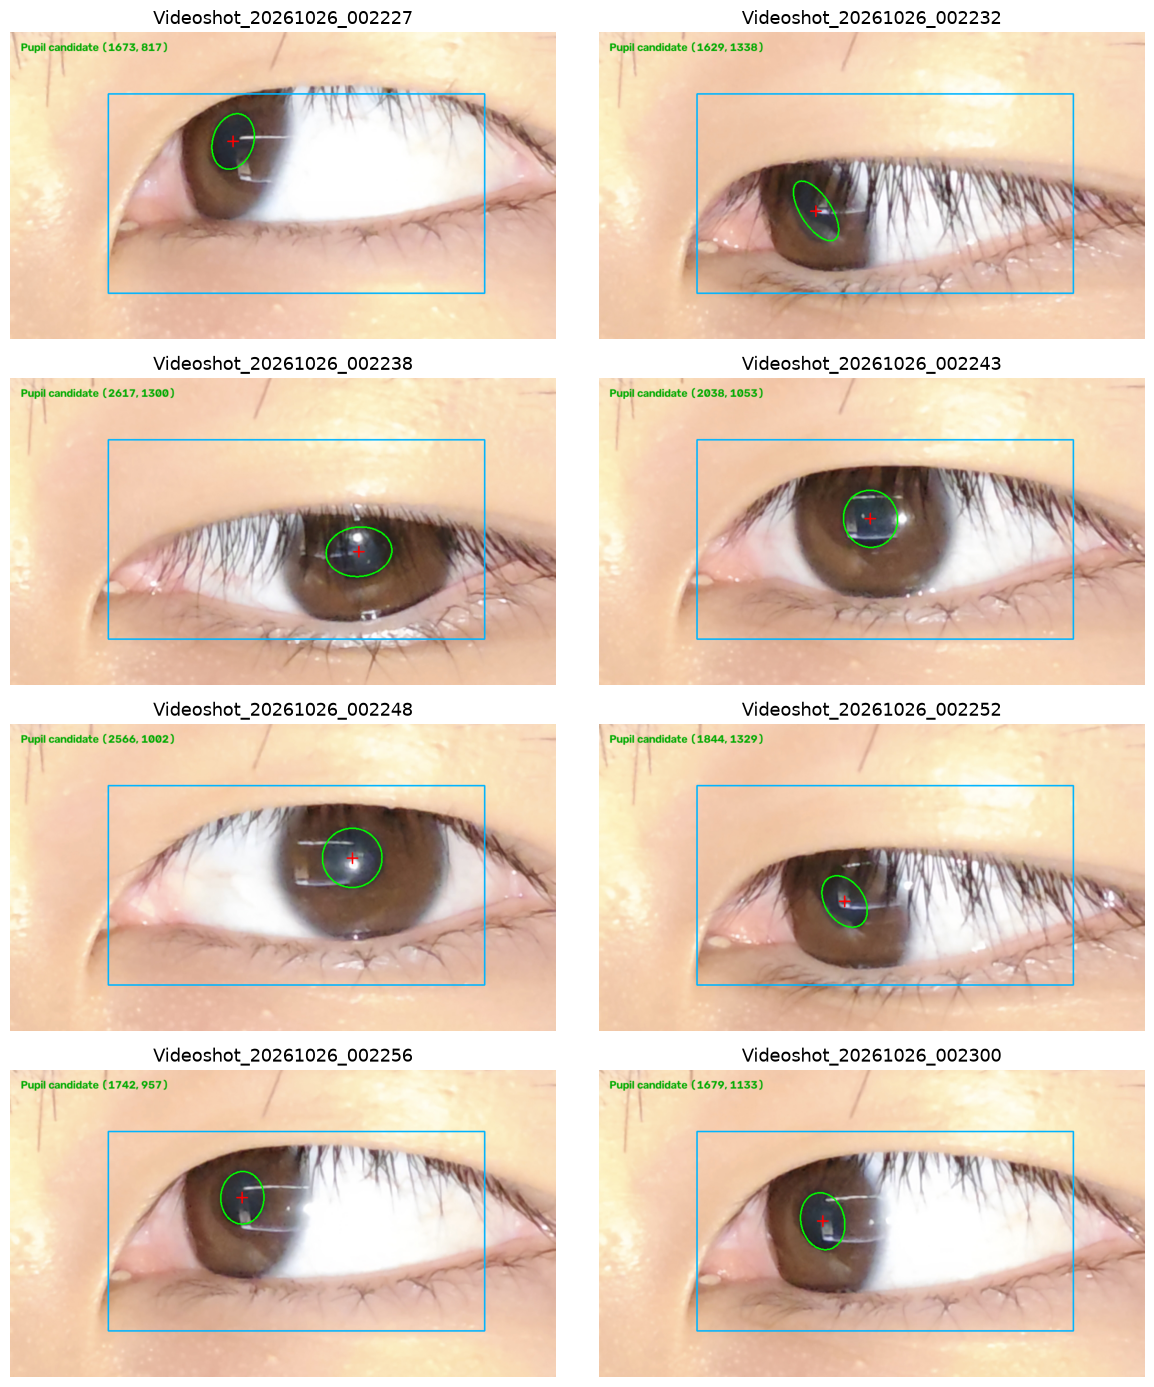

Videoshot_20261026_002227.jpg ứng viên: True ms: 30.28
Videoshot_20261026_002232.jpg ứng viên: True ms: 30.63
Videoshot_20261026_002238.jpg ứng viên: True ms: 33.7
Videoshot_20261026_002243.jpg ứng viên: True ms: 31.24
Videoshot_20261026_002248.jpg ứng viên: True ms: 33.81
Videoshot_20261026_002252.jpg ứng viên: True ms: 36.18
Videoshot_20261026_002256.jpg ứng viên: True ms: 30.52
Videoshot_20261026_002300.jpg ứng viên: True ms: 31.81


In [14]:
image_paths = sorted(p for p in DATA_DIR.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
batch_records, batch_images, batch_titles = [], [], []
for path in image_paths:
    batch_metrics, batch_stages = analyze(read_image(path), threshold=THRESHOLD)
    batch_records.append({'file': path.name, **batch_metrics})
    batch_images.append(batch_stages['result'])
    batch_titles.append(path.stem)
if batch_images:
    show(batch_images, batch_titles, columns=2)
    for row in batch_records:
        print(row['file'], 'ứng viên:', row['detected'], 'ms:', row['processing_ms'])
else:
    print('Không có ảnh trong thư mục data.')

## 13. Lưu kết quả
Lưu PNG các bước của ảnh và điều kiện đang chọn cùng số đo trong `output/notebook`. Đây là thư mục riêng, không ghi đè kết quả demo HTML. Chạy lại cùng tên ảnh và điều kiện sẽ cập nhật kết quả notebook tương ứng.

In [15]:
NOTEBOOK_OUTPUT = ROOT / 'output' / 'notebook' / Path(IMAGE_NAME).stem / CONDITION
NOTEBOOK_OUTPUT.mkdir(parents=True, exist_ok=True)
for name, img in stages.items():
    ok, encoded = cv2.imencode('.png', img)
    if not ok:
        raise RuntimeError(f'Không mã hóa được bước {name}')
    encoded.tofile(str(NOTEBOOK_OUTPUT / f'{name}.png'))
(NOTEBOOK_OUTPUT / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
if batch_records:
    fields = list(dict.fromkeys(key for row in batch_records for key in row))
    with (NOTEBOOK_OUTPUT / 'batch_metrics.csv').open('w', newline='', encoding='utf-8-sig') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(batch_records)
print('Đã lưu kết quả trong output/notebook.')

Đã lưu kết quả trong output/notebook.


## Kết luận khi trình bày
Notebook minh họa được hiệu chỉnh mức sáng, giảm nhiễu, tăng tương phản, phân đoạn và trích đặc trưng hình dạng. Kết quả trên tám ảnh chưa đủ để khẳng định hiệu quả tổng quát. Vùng cháy sáng, phản xạ lớn và che khuất vẫn là hạn chế. Bước tiếp theo là bổ sung dữ liệu có nhãn tâm, kiểm thử nhiều điều kiện và hiệu chuẩn điểm nhìn.